In [1]:
# 1) Importamos las librerías con sus alias convencionales
import matplotlib.pyplot as plt  # gráficos base (Seaborn se apoya en él)
import numpy as np  # cálculo numérico y condiciones vectorizadas
import pandas as pd  # tablas (DataFrame)
import seaborn as sns  # gráficos estadísticos de alto nivel
from scipy import stats  # pruebas estadísticas (Parte 6)

from flows.common.paths import BRONZE, BRONZE_LABELED_NAME, SILVER, SILVER_NAME

# 2) Estilo global: todos los gráficos heredan esta configuración
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (8, 5)   # tamaño por defecto (ancho, alto) en pulgadas
plt.rcParams['axes.titlesize'] = 13

# 3) Cargamos Bronze (nunca la URL: la ingesta ya la guardó)
df = pd.read_csv(BRONZE / BRONZE_LABELED_NAME)

In [2]:
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0.0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1.0,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0.0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1.0,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [3]:
df.shape

(891, 12)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    float64
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(3), int64(4), object(5)
memory usage: 83.7+ KB


In [5]:
df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0.0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0.0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0.0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1.0,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1.0,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [6]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
df.select_dtypes(exclude='number').describe()

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Dooley, Mr. Patrick",male,1601,G6,S
freq,1,577,7,4,644


In [8]:
(df['Age'] < 16).groupby(df['Pclass']).mean()

Pclass
1    0.027778
2    0.103261
3    0.118126
Name: Age, dtype: float64

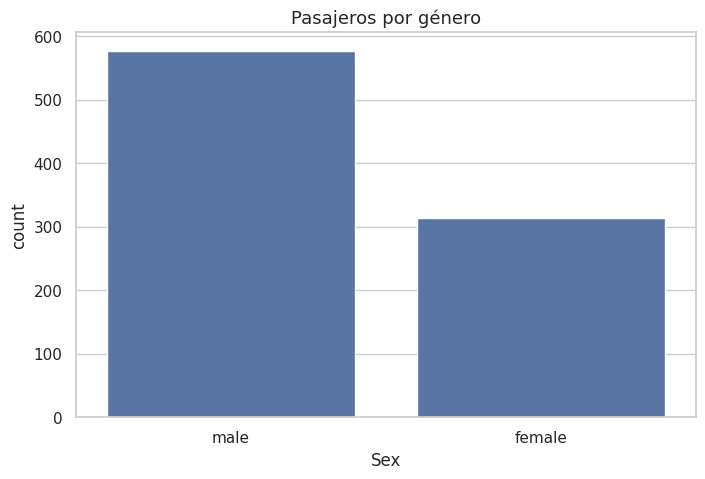

In [9]:
sns.countplot(data=df, x='Sex')
plt.title('Pasajeros por género'); plt.show()

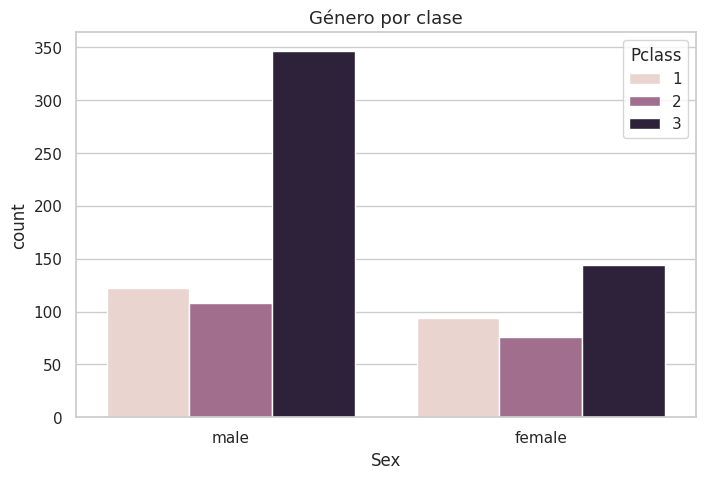

In [10]:
sns.countplot(data=df, x='Sex', hue='Pclass')
plt.title('Género por clase'); plt.show()

In [11]:
pd.crosstab(df['Sex'], df['Pclass'], normalize='columns').round(3)

Pclass,1,2,3
Sex,,,
female,0.435,0.413,0.293
male,0.565,0.587,0.707


In [12]:
df.describe()
df.select_dtypes(exclude='number').describe()

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Dooley, Mr. Patrick",male,1601,G6,S
freq,1,577,7,4,644


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


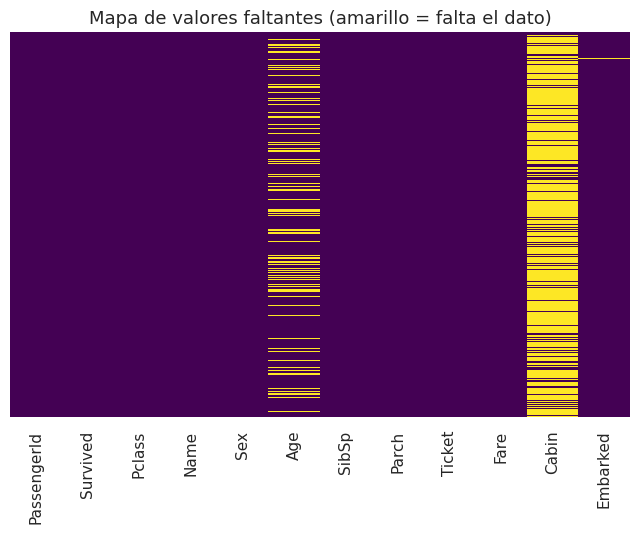

In [13]:
print(df.isnull().sum())
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Mapa de valores faltantes (amarillo = falta el dato)')
plt.show()

In [14]:
df = pd.read_parquet(SILVER / SILVER_NAME)
df.shape

(891, 25)

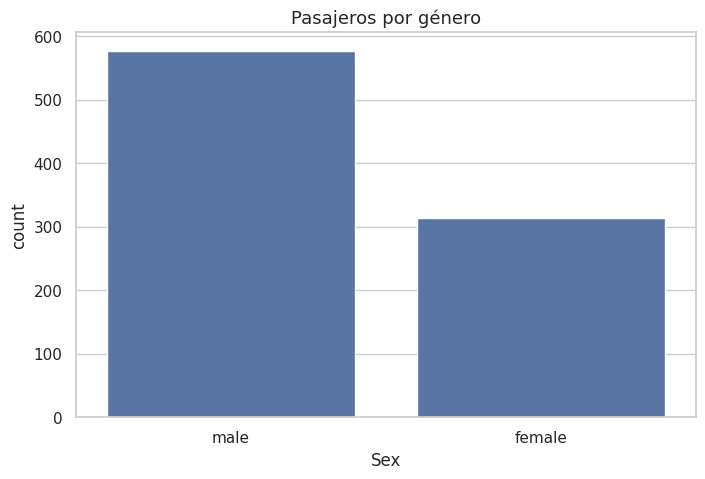

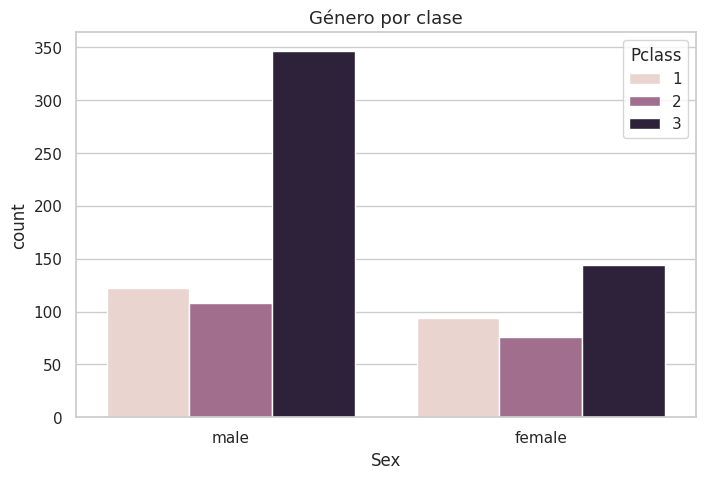

Pclass,1,2,3
Sex,,,
female,0.435,0.413,0.293
male,0.565,0.587,0.707


In [15]:
sns.countplot(data=df, x='Sex')
plt.title('Pasajeros por género'); plt.show()

sns.countplot(data=df, x='Sex', hue='Pclass')
plt.title('Género por clase'); plt.show()

pd.crosstab(df['Sex'], df['Pclass'], normalize='columns').round(3)

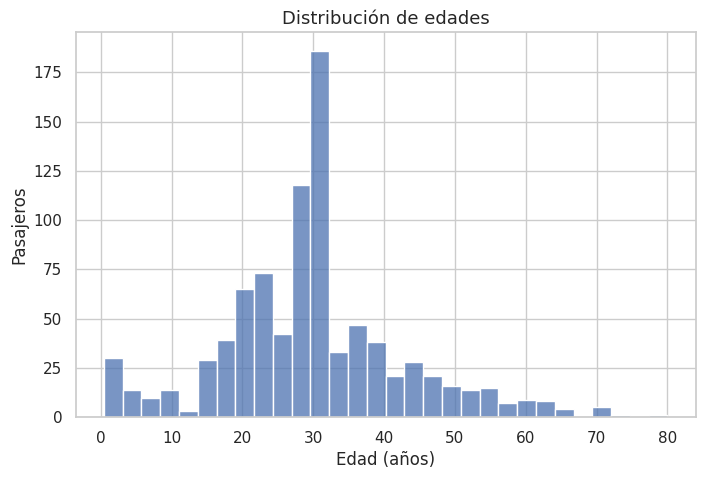

(np.float64(30.0), np.float64(0.42), np.float64(80.0))

In [16]:
sns.histplot(df['Age'].dropna(), bins=30)
plt.title('Distribución de edades'); plt.xlabel('Edad (años)'); plt.ylabel('Pasajeros'); plt.show()
df['Age'].mean()
df['Age'].median(), df['Age'].min(), df['Age'].max()

In [17]:
df['Person'] = np.where(df['Age'] < 16, 'child', df['Sex'])
df['Person'].value_counts()

Person
male      537
female    271
child      83
Name: count, dtype: int64

In [18]:
pd.crosstab(df['Pclass'], df['Person'])

Person,child,female,male
Pclass,,,
1,6,91,119
2,19,66,99
3,58,114,319


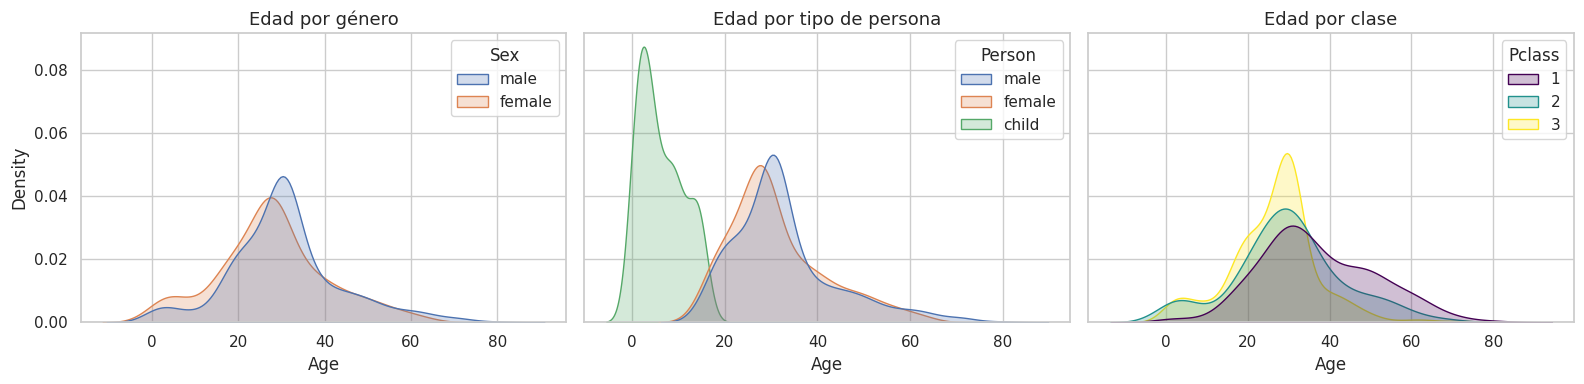

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
sns.kdeplot(data=df, x='Age', hue='Sex', fill=True, common_norm=False, ax=axes[0])
sns.kdeplot(data=df, x='Age', hue='Person', fill=True, common_norm=False, ax=axes[1])
sns.kdeplot(data=df, x='Age', hue='Pclass', fill=True, common_norm=False, palette='viridis', ax=axes[2])
axes[0].set_title('Edad por género')
axes[1].set_title('Edad por tipo de persona')
axes[2].set_title('Edad por clase')
plt.tight_layout(); plt.show()

In [20]:
cabinas = df['Cabin'].dropna()
cubierta = cabinas.str[0]
cubierta.value_counts() 

Cabin
C    59
B    47
D    33
E    32
A    15
F    13
G     4
T     1
Name: count, dtype: int64

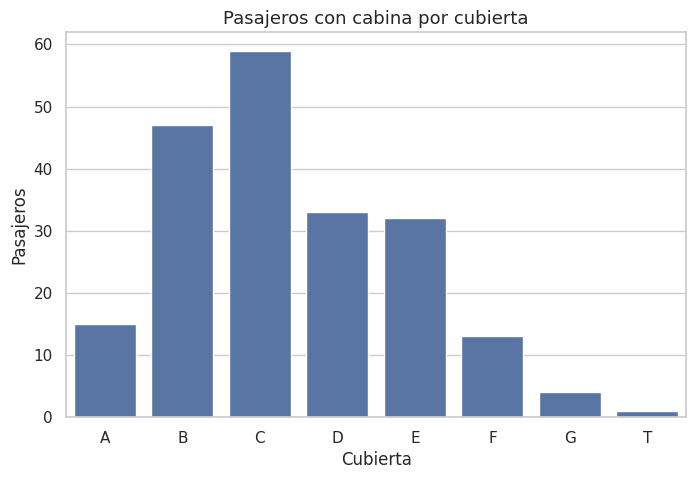

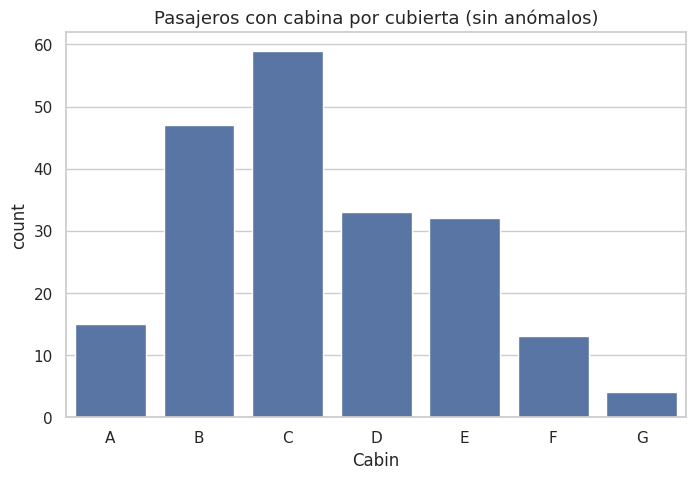

In [21]:
orden = sorted(cubierta.unique())
sns.countplot(x=cubierta, order=orden)
plt.title('Pasajeros con cabina por cubierta'); plt.xlabel('Cubierta'); plt.ylabel('Pasajeros'); plt.show()

# La cubierta 'T' tiene un solo registro (anómalo: el barco no tenía cubierta T de pasajeros normales)
cubierta = cubierta[cubierta != 'T']
sns.countplot(x=cubierta, order=sorted(cubierta.unique()))
plt.title('Pasajeros con cabina por cubierta (sin anómalos)'); plt.show()


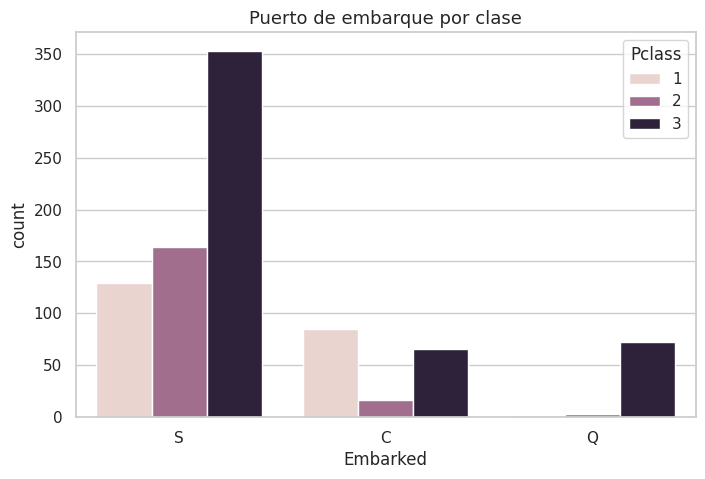

Pclass,1,2,3
Embarked,,,
C,0.506,0.101,0.393
Q,0.026,0.039,0.935
S,0.200,0.254,0.546


In [22]:
sns.countplot(data=df, x='Embarked', hue='Pclass', order=['S', 'C', 'Q'])
plt.title('Puerto de embarque por clase'); plt.show()
pd.crosstab(df['Embarked'], df['Pclass'], normalize='index').round(3)


In [23]:
df['Familia'] = df['SibSp'] + df['Parch']
df['Alone'] = np.where(df['Familia'] > 0, 'with Family', 'Alone')
df['Alone'].value_counts(normalize=True)

Alone
Alone          0.602694
with Family    0.397306
Name: proportion, dtype: float64

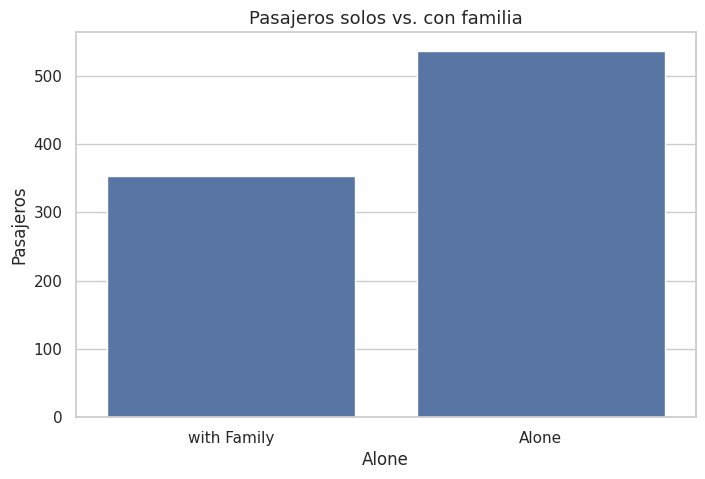

In [24]:
sns.countplot(data=df, x='Alone')
plt.title('Pasajeros solos vs. con familia'); plt.ylabel('Pasajeros'); plt.show()

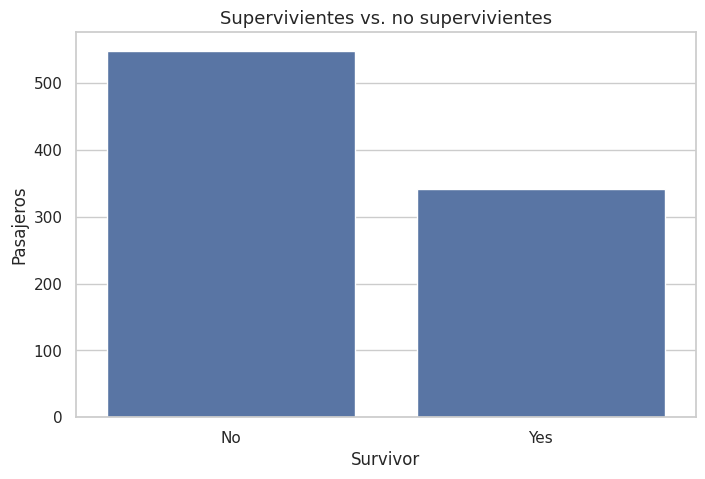

np.float64(0.3838383838383838)

In [25]:
df['Survivor'] = df['Survived'].map({0: 'No', 1: 'Yes'})
sns.countplot(data=df, x='Survivor')
plt.title('Supervivientes vs. no supervivientes'); plt.ylabel('Pasajeros'); plt.show()
df['Survived'].mean() 


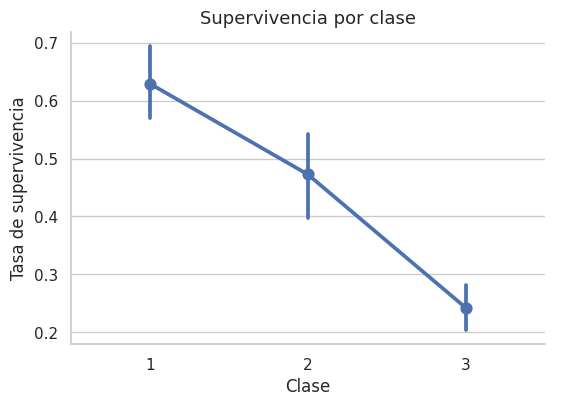

In [26]:
g = sns.catplot(data=df, x='Pclass', y='Survived', kind='point', height=4, aspect=1.4)
g.set_axis_labels('Clase', 'Tasa de supervivencia')
plt.title('Supervivencia por clase'); plt.show()


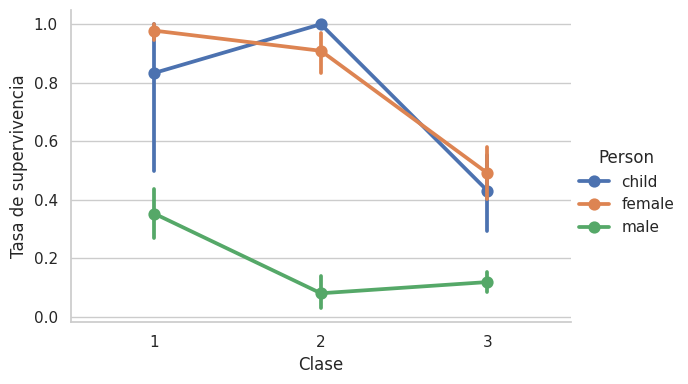

In [27]:
g = sns.catplot(data=df, x='Pclass', y='Survived', hue='Person', kind='point',
                hue_order=['child', 'female', 'male'], height=4, aspect=1.5)
g.set_axis_labels('Clase', 'Tasa de supervivencia')
plt.show()

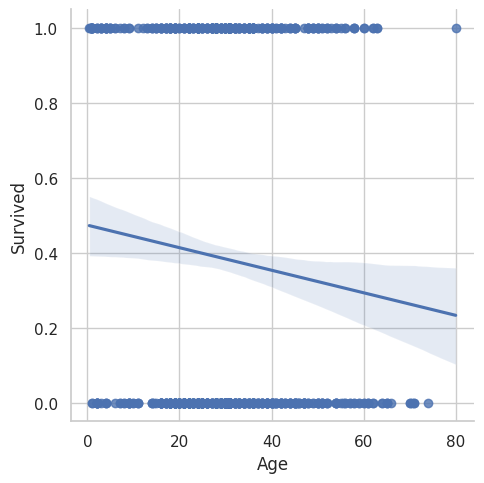

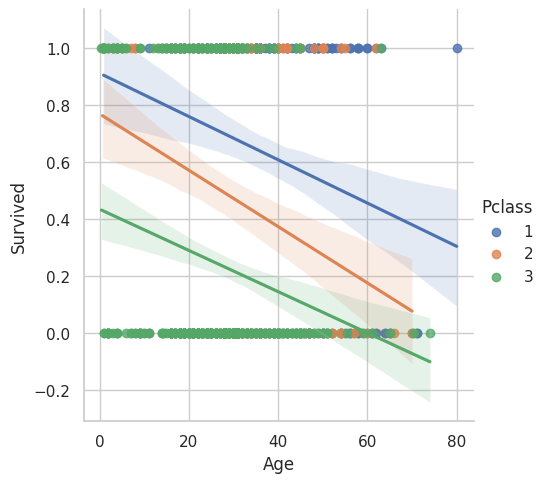

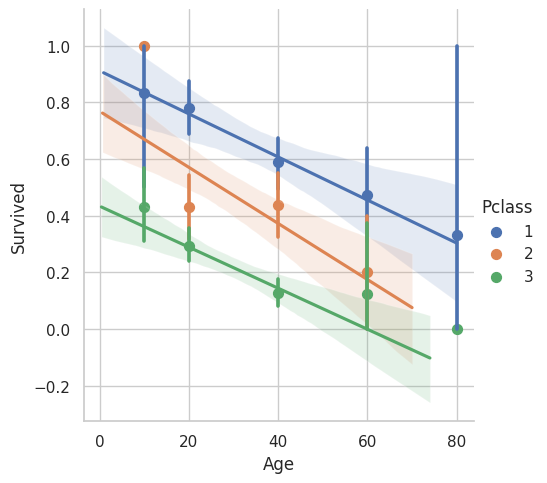

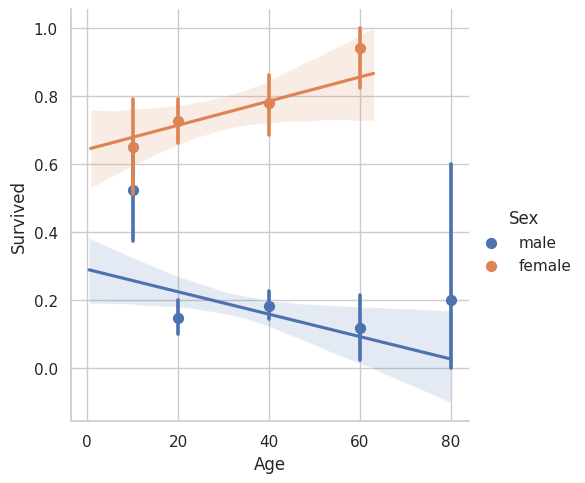

In [28]:
sns.lmplot(data=df, x='Age', y='Survived')
sns.lmplot(data=df, x='Age', y='Survived', hue='Pclass')
generaciones = [10, 20, 40, 60, 80]
sns.lmplot(data=df, x='Age', y='Survived', hue='Pclass', x_bins=generaciones)
sns.lmplot(data=df, x='Age', y='Survived', hue='Sex', x_bins=generaciones)
plt.show()

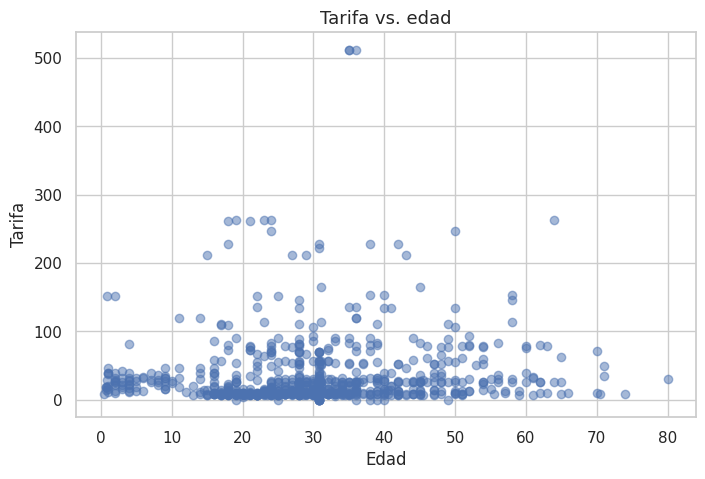

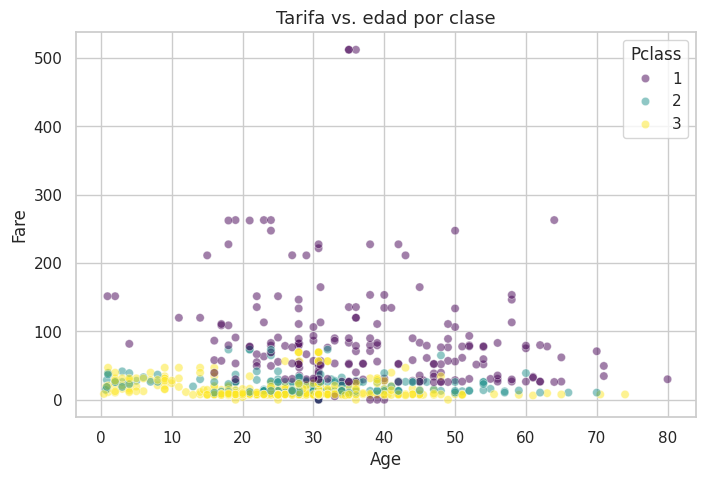

In [29]:
plt.scatter(df['Age'], df['Fare'], alpha=0.5)
plt.xlabel('Edad'); plt.ylabel('Tarifa'); plt.title('Tarifa vs. edad'); plt.show()

sns.scatterplot(data=df, x='Age', y='Fare', hue='Pclass', alpha=0.5, palette='viridis')
plt.title('Tarifa vs. edad por clase'); plt.show()

In [30]:
df['Embarked'].isnull().sum() 
moda = df['Embarked'].mode()[0]
df['Embarked'] = df['Embarked'].fillna(moda)
df['NEmbarked'] = df['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})


In [31]:
std_antes = df['Age'].std() 
promedios = df.groupby('Sex')['Age'].mean()
df['Age'] = df['Age'].fillna(df['Sex'].map(promedios))
df['Age'].isnull().sum()  

np.int64(0)

In [32]:
df['NSex'] = df['Sex'].map({'female': 0, 'male': 1})

In [33]:
df['Cabin'] = df['Cabin'].fillna('X')
df['TCabin'] = df['Cabin'].str[0]
df['TCabin'].value_counts() 
mapa = {letra: i for i, letra in enumerate(sorted(df['TCabin'].unique()))}
df['NCabin'] = df['TCabin'].map(mapa)

In [34]:
df['TTitulo'] = df['Name'].str.extract(r',\s*([^.]+)\.', expand=False).str.strip()
df['TTitulo'].value_counts()  
pd.crosstab(df['TTitulo'], df['Sex'])

Sex,female,male
TTitulo,,
Capt,0,1
Col,0,2
Don,0,1
Dr,1,6
Jonkheer,0,1
Lady,1,0
Major,0,2
Master,0,40
Miss,182,0


In [35]:
reemplazos = {'Master': 'Mr',
              'the Countess': 'Mrs', 'Dona': 'Mrs', 'Mme': 'Mrs',
              'Lady': 'Miss', 'Mlle': 'Miss', 'Ms': 'Miss'}
df['TTitulo'] = df['TTitulo'].replace(reemplazos)
df['TTitulo'] = df['TTitulo'].where(df['TTitulo'].isin(['Mr', 'Mrs', 'Miss']), 'Otro')
df['TTitulo'].value_counts()
df['NTitulo'] = df['TTitulo'].map({'Mr': 0, 'Mrs': 1, 'Miss': 2, 'Otro': 3})

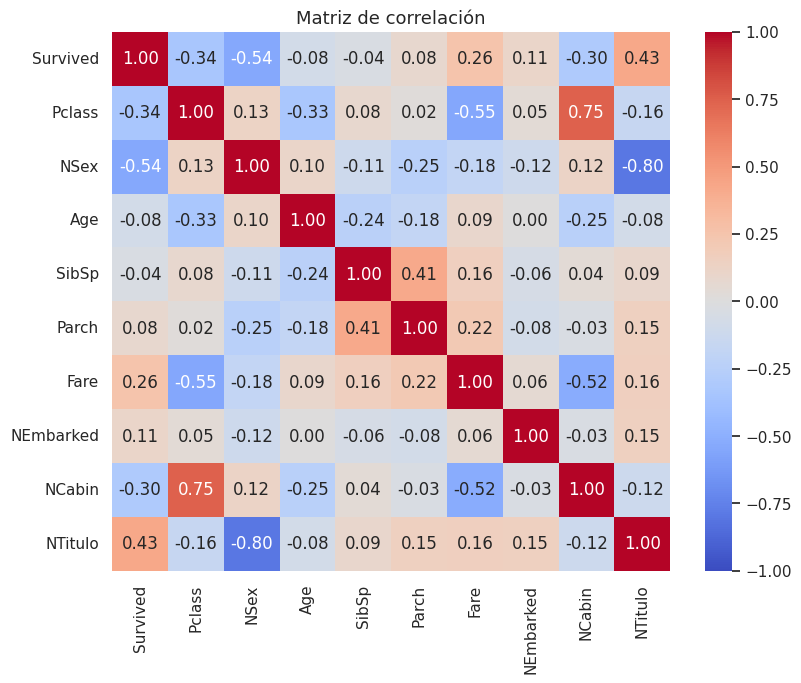

NSex        -0.543351
Pclass      -0.338481
NCabin      -0.301116
Age         -0.080453
SibSp       -0.035322
Parch        0.081629
NEmbarked    0.106811
Fare         0.257307
NTitulo      0.428661
Survived     1.000000
Name: Survived, dtype: float64

In [36]:
cols = ['Survived', 'Pclass', 'NSex', 'Age', 'SibSp', 'Parch', 'Fare', 'NEmbarked', 'NCabin', 'NTitulo']
corr = df[cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Matriz de correlación'); plt.show()
corr['Survived'].sort_values()


In [37]:
df.groupby('Survived')['Age'].describe()
df.groupby('Sex')['Survived'].agg(['mean', 'sum', 'count'])
df.groupby('Pclass')['Survived'].agg(['mean', 'sum', 'count'])
df.groupby('Alone')['Survived'].agg(['mean', 'sum', 'count'])

,mean,sum,count
Alone,,,
Alone,0.303538,163,537
with Family,0.505650,179,354


In [38]:
tabla = pd.crosstab(df['Sex'], df['Survived'])
chi2, p, gl, esperados = stats.chi2_contingency(tabla)
print(f'chi2 = {chi2:.1f}, p = {p:.2e}, gl = {gl}')
# p del orden de 1e-58  ->  se rechaza H0: Sex y Survived NO son independientes

chi2 = 260.7, p = 1.20e-58, gl = 1


In [39]:
tabla_c = pd.crosstab(df['Pclass'], df['Survived'])
chi2_c, p_c, gl_c, esp_c = stats.chi2_contingency(tabla_c)
print(f'chi2 = {chi2_c:.1f}, p = {p_c:.2e}') 

chi2 = 102.9, p = 4.55e-23


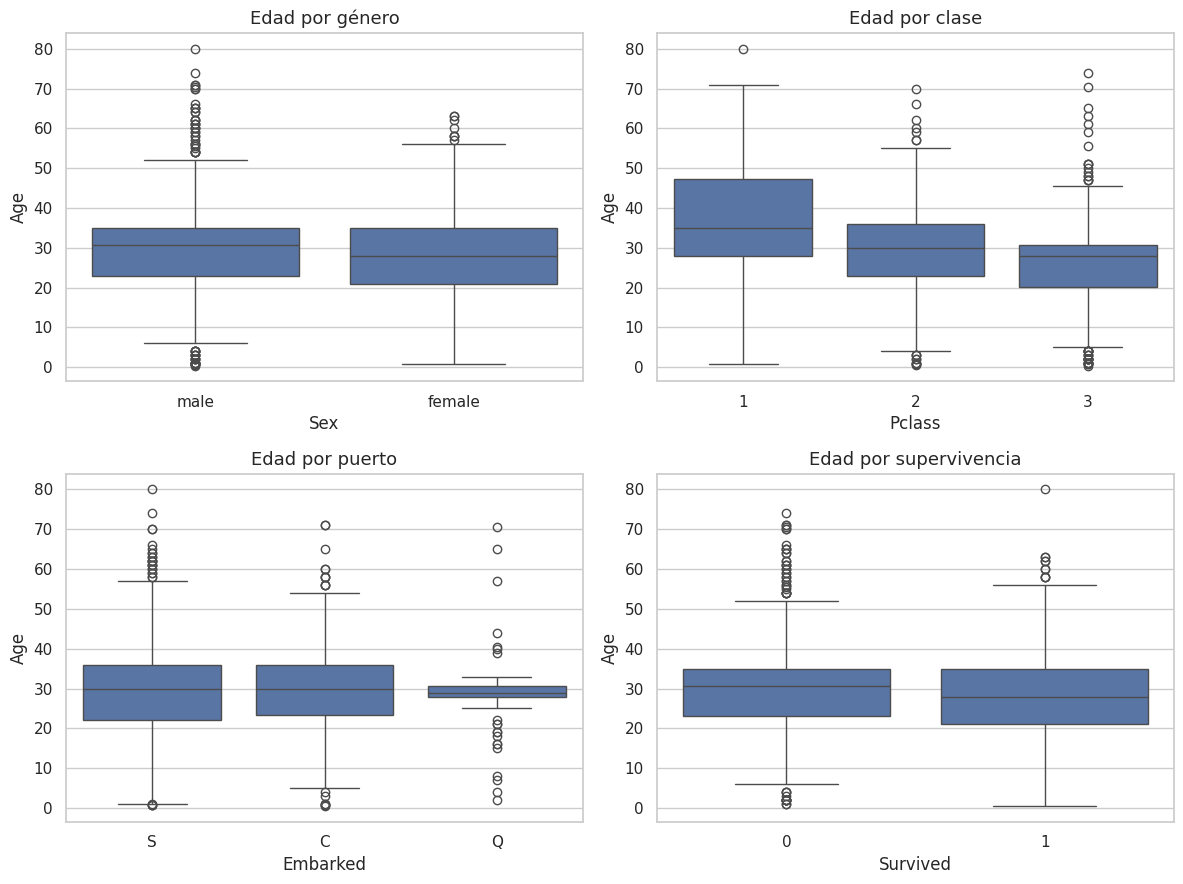

In [40]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
sns.boxplot(data=df, x='Sex', y='Age', ax=axes[0, 0])
sns.boxplot(data=df, x='Pclass', y='Age', ax=axes[0, 1])
sns.boxplot(data=df, x='Embarked', y='Age', ax=axes[1, 0])
sns.boxplot(data=df, x='Survived', y='Age', ax=axes[1, 1])
axes[0, 0].set_title('Edad por género'); axes[0, 1].set_title('Edad por clase')
axes[1, 0].set_title('Edad por puerto'); axes[1, 1].set_title('Edad por supervivencia')
plt.tight_layout(); plt.show()


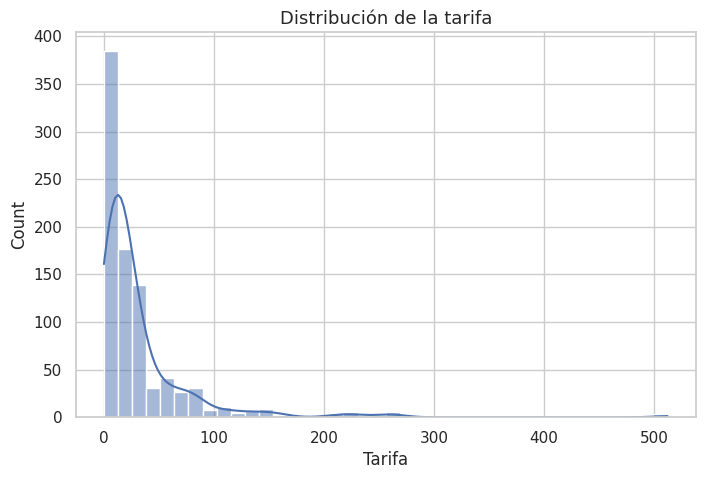

(np.float64(32.204207968574636),
 np.float64(14.4542),
 np.float64(4.787316519674893))

In [41]:
sns.histplot(df['Fare'], kde=True, bins=40)
plt.title('Distribución de la tarifa'); plt.xlabel('Tarifa'); plt.show()
df['Fare'].mean(), df['Fare'].median(), df['Fare'].skew()

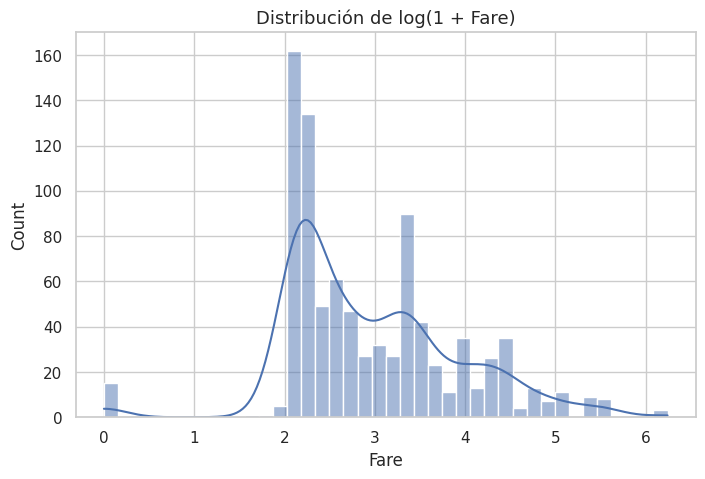

In [42]:
sns.histplot(np.log1p(df['Fare']), kde=True, bins=40)
plt.title('Distribución de log(1 + Fare)'); plt.show()

In [43]:
df_final = df.drop(columns=['Name', 'Sex', 'Embarked', 'Cabin'])


In [44]:
display(df_final.isnull().sum())
display(df_final.dtypes)
df_final.info()
df_final.describe()

PassengerId      0
Survived         0
Pclass           0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Person           0
TCabin           0
HasCabin         0
Familia          0
Alone            0
Survivor         0
TTitulo          0
AgeOriginal    177
AgeImputada      0
NSex             0
NEmbarked        0
NCabin           0
NTitulo          0
dtype: int64

PassengerId      int64
Survived         int64
Pclass           int64
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Person          object
TCabin          object
HasCabin         int64
Familia          int64
Alone           object
Survivor        object
TTitulo         object
AgeOriginal    float64
AgeImputada       bool
NSex             int64
NEmbarked        int64
NCabin           int64
NTitulo          int64
dtype: object

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 21 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Age          891 non-null    float64
 4   SibSp        891 non-null    int64  
 5   Parch        891 non-null    int64  
 6   Ticket       891 non-null    object 
 7   Fare         891 non-null    float64
 8   Person       891 non-null    object 
 9   TCabin       891 non-null    object 
 10  HasCabin     891 non-null    int64  
 11  Familia      891 non-null    int64  
 12  Alone        891 non-null    object 
 13  Survivor     891 non-null    object 
 14  TTitulo      891 non-null    object 
 15  AgeOriginal  714 non-null    float64
 16  AgeImputada  891 non-null    bool   
 17  NSex         891 non-null    int64  
 18  NEmbarked    891 non-null    int64  
 19  NCabin  

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,HasCabin,Familia,AgeOriginal,NSex,NEmbarked,NCabin,NTitulo
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.736034,0.523008,0.381594,32.204208,0.228956,0.904602,29.699118,0.647587,0.361392,6.716049,0.630752
std,257.353842,0.486592,0.836071,13.014897,1.102743,0.806057,49.693429,0.420397,1.613459,14.526497,0.477990,0.635673,2.460739,0.890346
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000,0.000000,0.000000,0.420000,0.000000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400,0.000000,0.000000,20.125000,0.000000,0.000000,8.000000,0.000000
50%,446.000000,0.000000,3.000000,30.000000,0.000000,0.000000,14.454200,0.000000,0.000000,28.000000,1.000000,0.000000,8.000000,0.000000
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000,0.000000,1.000000,38.000000,1.000000,1.000000,8.000000,1.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200,1.000000,10.000000,80.000000,1.000000,2.000000,8.000000,3.000000


In [45]:
df_final['NAlone'] = df_final['Alone'].map({'with Family': 0, 'Alone': 1})
df_final['NPerson'] = df_final['Person'].map({'child': 0, 'female': 1, 'male': 2})

In [46]:
df.pivot_table(values='Survived', index='Pclass', columns='Sex', aggfunc='mean').round(3)

Sex,female,male
Pclass,,
1,0.968,0.369
2,0.921,0.157
3,0.500,0.135


In [47]:
df.groupby('Embarked')['Survived'].agg(['mean', 'count'])
df.pivot_table(values='Survived', index='Embarked', columns='Pclass', aggfunc='mean').round(2)

Pclass,1,2,3
Embarked,,,
C,0.69,0.53,0.38
Q,0.50,0.67,0.38
S,0.59,0.46,0.19


In [48]:
df['FareQ'] = df.groupby('Pclass')['Fare'].transform(
    lambda s: pd.qcut(s, 4, labels=False, duplicates='drop'))
df.pivot_table(values='Survived', index='FareQ', columns='Pclass', aggfunc='mean').round(2)


Pclass,1,2,3
FareQ,,,
0,0.46,0.35,0.23
1,0.57,0.50,0.20
2,0.75,0.58,0.28
3,0.74,0.59,0.28


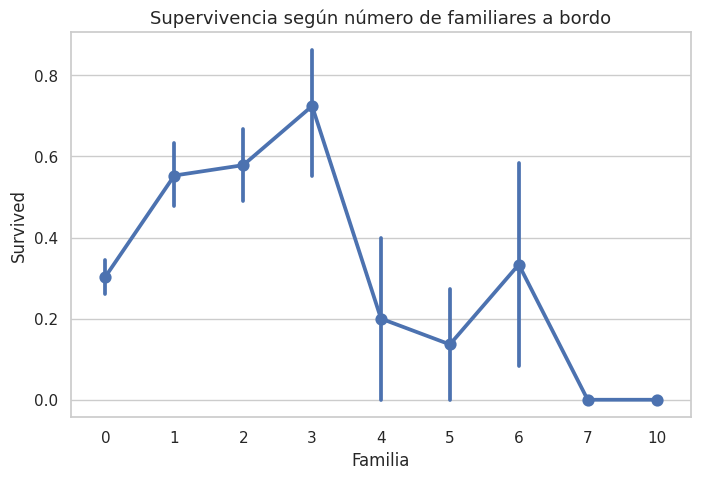

In [49]:
df.groupby('Familia')['Survived'].agg(['mean', 'count'])
sns.pointplot(data=df, x='Familia', y='Survived')
plt.title('Supervivencia según número de familiares a bordo'); plt.show()

In [50]:
def outliers_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)

for col in ['Fare', 'Age', 'Familia']:
    print(col, outliers_iqr(df[col]).sum())

mask_fare = outliers_iqr(df['Fare'])
df.groupby(mask_fare)['Survived'].agg(['mean', 'count'])
df.nlargest(10, 'Fare')[['Name', 'Pclass', 'Fare', 'Survived']]

tabla_a = pd.crosstab(df['Alone'], df['Survived'])
chi2_a, p_a, gl_a, esp_a = stats.chi2_contingency(tabla_a)
print(f'chi2 = {chi2_a:.1f}, p = {p_a:.2e}')

Fare 116
Age 66
Familia 91
chi2 = 36.0, p = 1.97e-09
